Analytics Spatial

Monica Anastasya Dantina 24/544527/TK/60525

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw/zenodo")
OUT = Path("../outputs/spatial"); OUT.mkdir(parents=True, exist_ok=True)

hourly = pd.read_csv(RAW/"presence_kapanewon_hourly.csv")
grid   = pd.read_csv(RAW/"presence_cell500m_daily.csv")
od     = pd.read_csv(RAW/"od_home_visits_kapanewon_monthly.csv")

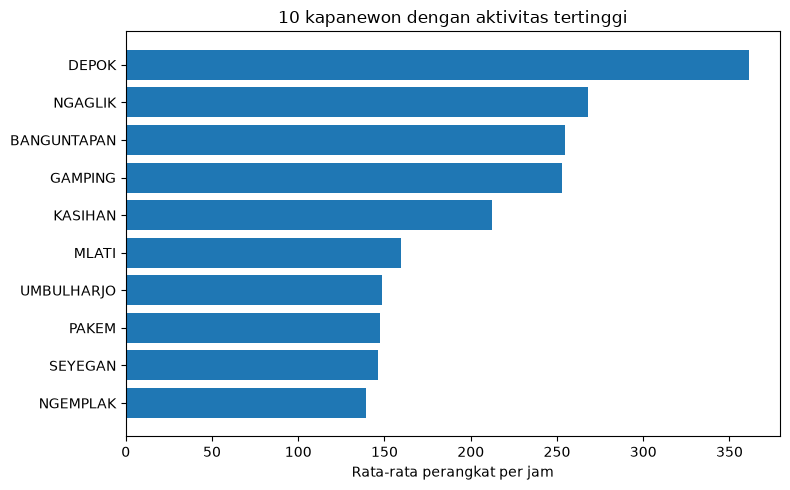

In [2]:
# rata-rata perangkat per jam, per kapanewon
act = (hourly.groupby(["kapanewon_code","kapanewon","kab_kota"], as_index=False)
             .agg(avg_maids=("n_maids","mean"), total_pings=("n_pings","sum")))
top10 = act.sort_values("avg_maids", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top10["kapanewon"][::-1], top10["avg_maids"][::-1])
ax.set_xlabel("Rata-rata perangkat per jam")
ax.set_title("10 kapanewon dengan aktivitas tertinggi")
plt.tight_layout(); plt.savefig(OUT/"top10_kapanewon.png", dpi=200)

,cell_id,centroid_lon,centroid_lat,avg_daily
1755,E845_N18275,110.299351,-7.799984,1546.405941
1777,E845_N18297,110.299515,-7.700489,1363.485437
2790,E859_N18274,110.362830,-7.804607,1264.456954
4600,E886_N18296,110.485393,-7.705275,872.600000
3913,E874_N18307,110.431053,-7.655458,852.860465
3412,E867_N18297,110.399257,-7.700641,729.256000
3260,E865_N18299,110.390202,-7.691583,680.863636
2663,E857_N18294,110.353899,-7.714142,582.158940
3390,E867_N18275,110.399116,-7.800138,521.612403
3249,E865_N18288,110.390131,-7.741331,450.649007


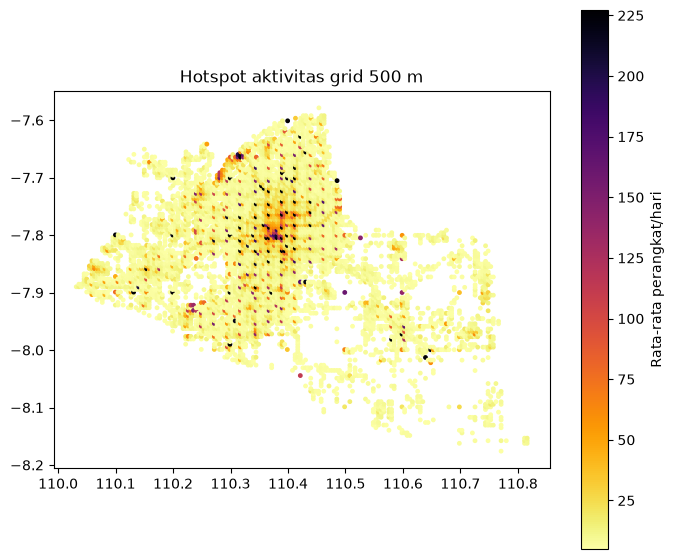

In [3]:
cell = (grid.groupby(["cell_id","centroid_lon","centroid_lat"], as_index=False)
            .agg(avg_daily=("n_maids","mean")))

fig, ax = plt.subplots(figsize=(8,7))
sc = ax.scatter(cell["centroid_lon"], cell["centroid_lat"],
                c=cell["avg_daily"], s=6, cmap="inferno_r", vmax=cell["avg_daily"].quantile(0.99))
plt.colorbar(sc, label="Rata-rata perangkat/hari")
ax.set_title("Hotspot aktivitas grid 500 m"); ax.set_aspect("equal")
plt.savefig(OUT/"hotspot_grid.png", dpi=200)

cell.sort_values("avg_daily", ascending=False).head(10)  # sel-sel teraktif

In [4]:
inter = od[od["origin_code"] != od["dest_code"]]          # arus antar kapanewon
flow = (inter.groupby(["origin_kapanewon","dest_kapanewon"], as_index=False)["n_maids"].sum()
             .sort_values("n_maids", ascending=False))
flow.head(10)

# kapanewon "penarik" vs "pengirim"
inflow  = inter.groupby("dest_kapanewon")["n_maids"].sum()
outflow = inter.groupby("origin_kapanewon")["n_maids"].sum()
net = (inflow.sub(outflow, fill_value=0)).sort_values(ascending=False)
net.head(5), net.tail(5)   # net inflow terbesar vs net outflow terbesar

(dest_kapanewon
 GONDOKUSUMAN    8629
 DANUREJAN       4160
 JETIS           3541
 MERGANGSAN      3310
 TEGALREJO       2979
 Name: n_maids, dtype: int64,
 dest_kapanewon
 SEYEGAN       -3285
 NGAGLIK       -4515
 KASIHAN       -4961
 BANGUNTAPAN   -7235
 GAMPING       -8499
 Name: n_maids, dtype: int64)

In [6]:
import geopandas as gpd
from pathlib import Path

print(list(Path("../data/raw/boundaries").iterdir()))   # lihat nama file-nya

[WindowsPath('../data/raw/boundaries/gadm_diy.geojson'), WindowsPath('../data/raw/boundaries/kapanewon_diy_boundary.geojson'), WindowsPath('../data/raw/boundaries/kapanewon_lookup.csv')]


In [7]:
import geopandas as gpd
import pandas as pd

gdf = gpd.read_file("../data/raw/boundaries/kapanewon_diy_boundary.geojson")
lookup = pd.read_csv("../data/raw/boundaries/kapanewon_lookup.csv")

print(gdf.shape)
print(gdf.columns.tolist())
display(gdf.drop(columns="geometry").head())

print(lookup.shape)
print(lookup.columns.tolist())
display(lookup.head())

(78, 11)
['id', 'code', 'bps_code', 'name', 'parent_id', 'parent_name', 'source', 'kapanewon_clean', 'kab_kota_clean', 'join_key', 'geometry']


,id,code,bps_code,name,parent_id,parent_name,source,kapanewon_clean,kab_kota_clean,join_key
0,34.01.01,34.01.01,34.01.01,KEC. TEMON,34.01,KAB. KULON PROGO,cahyadsn,TEMON,KULON PROGO,34.01.01
1,34.01.02,34.01.02,34.01.02,KEC. WATES,34.01,KAB. KULON PROGO,cahyadsn,WATES,KULON PROGO,34.01.02
2,34.01.03,34.01.03,34.01.03,KEC. PANJATAN,34.01,KAB. KULON PROGO,cahyadsn,PANJATAN,KULON PROGO,34.01.03
3,34.01.04,34.01.04,34.01.04,KEC. GALUR,34.01,KAB. KULON PROGO,cahyadsn,GALUR,KULON PROGO,34.01.04
4,34.01.05,34.01.05,34.01.05,KEC. LENDAH,34.01,KAB. KULON PROGO,cahyadsn,LENDAH,KULON PROGO,34.01.05


(78, 3)
['kapanewon_code', 'kab_kota', 'kapanewon']


,kapanewon_code,kab_kota,kapanewon
0,34.01.01,KULON PROGO,TEMON
1,34.01.02,KULON PROGO,WATES
2,34.01.03,KULON PROGO,PANJATAN
3,34.01.04,KULON PROGO,GALUR
4,34.01.05,KULON PROGO,LENDAH


Kapanewon tanpa data: 0


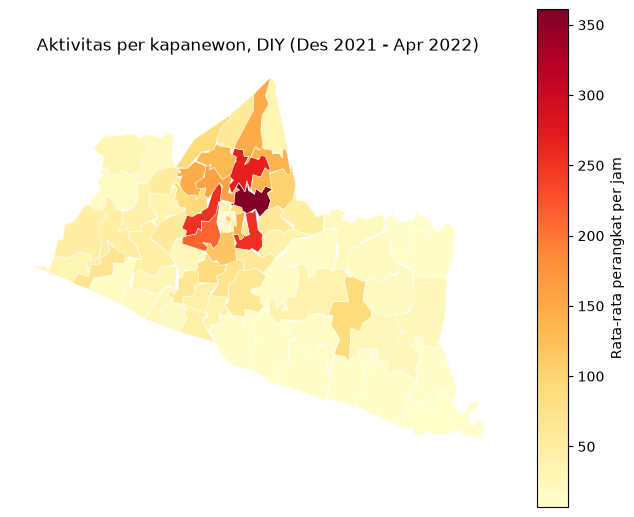

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt

gdf = gpd.read_file("../data/raw/boundaries/kapanewon_diy_boundary.geojson")

# sambungkan peta dengan angka aktivitas
peta = gdf.merge(act, left_on="join_key", right_on="kapanewon_code", how="left")

# cek: ada kapanewon yang tidak punya angka?
print("Kapanewon tanpa data:", peta["avg_maids"].isna().sum())

# gambar petanya
fig, ax = plt.subplots(figsize=(8, 8))
peta.plot(column="avg_maids", cmap="YlOrRd", legend=True,
          edgecolor="white", linewidth=0.4, ax=ax,
          legend_kwds={"label": "Rata-rata perangkat per jam"})
ax.set_title("Aktivitas per kapanewon, DIY (Des 2021 - Apr 2022)")
ax.axis("off")
plt.savefig(OUT/"choropleth_kapanewon.png", dpi=200, bbox_inches="tight")

,origin_kapanewon,dest_kapanewon,n_maids
1506,NGAGLIK,DEPOK,3670
103,BANGUNTAPAN,UMBULHARJO,3471
1536,NGAGLIK,PAKEM,3431
1534,NGAGLIK,NGEMPLAK,3193
1610,NGEMPLAK,DEPOK,3096
1630,NGEMPLAK,NGAGLIK,2975
41,BANGUNTAPAN,DEPOK,2920
316,DEPOK,NGEMPLAK,2788
294,DEPOK,GONDOKUSUMAN,2750
282,DEPOK,BANGUNTAPAN,2731


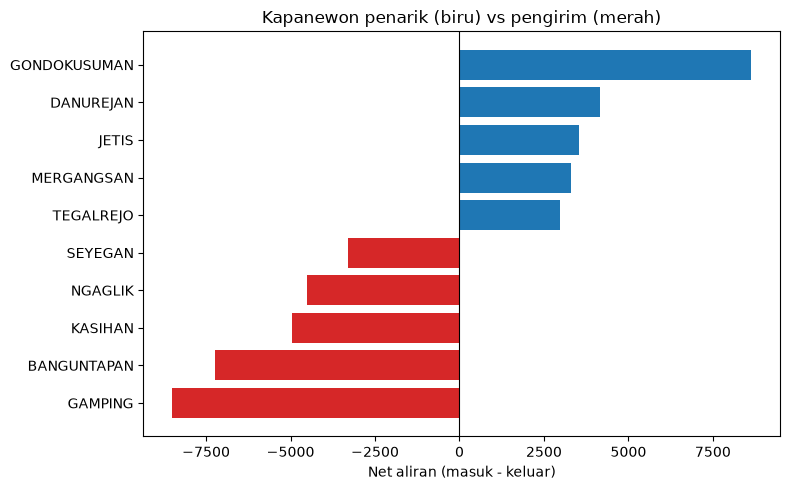

In [9]:
# top 10 pasangan asal -> tujuan
top_flow = flow.head(10)
display(top_flow)
top_flow.to_csv(OUT/"top10_od_pairs.csv", index=False)

# grafik net inflow vs outflow
net_plot = pd.concat([net.head(5), net.tail(5)])
colors = ["tab:blue" if v > 0 else "tab:red" for v in net_plot]
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(net_plot.index[::-1], net_plot.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Net aliran (masuk - keluar)")
ax.set_title("Kapanewon penarik (biru) vs pengirim (merah)")
plt.tight_layout(); plt.savefig(OUT/"net_flow.png", dpi=200)

# simpan tabel pendukung buat Anggota 7
act.to_csv(OUT/"activity_per_kapanewon.csv", index=False)
net.rename("net_flow").to_csv(OUT/"net_flow_per_kapanewon.csv")

## Insight Spatial Analytics

1. **Aktivitas terkonsentrasi di aglomerasi Yogyakarta.** Depok tertinggi (sekitar 360 perangkat/jam), diikuti Ngaglik, Banguntapan, Gamping, dan Kasihan (sekitar 210-270). Kapanewon di Gunungkidul dan Kulon Progo jauh lebih sepi.
2. **Hotspot grid 500 m sangat timpang.** Sel teraktif rata-rata sekitar 1.546 perangkat/hari, sedangkan sel ke-10 sekitar 450, dan sel-sel teratas mengelompok di sekitar kota.
3. **Kota Yogyakarta jadi tujuan.** Net inflow terbesar: Gondokusuman (+8.629), Danurejan, Jetis, Mergangsan, Tegalrejo.
4. **Wilayah pinggiran jadi asal kunjungan.** Net outflow terbesar: Gamping (-8.499), Banguntapan, Kasihan, Ngaglik, Seyegan. Ini mengindikasikan pola tinggal di pinggiran dan beraktivitas di kota.

**Keterbatasan:** angka adalah jumlah perangkat (bukan orang), data disensor k=5, angka OD dijumlahkan lintas bulan sehingga satu perangkat bisa terhitung berulang, dan belum dinormalisasi dengan jumlah penduduk (dibahas di analisis komparatif Anggota 7).